# 19 — Đánh giá Random Forest giữ nhóm

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Proxy label không phải ground truth; không có nhãn hazard đã xác minh hay quyết định human review nào được dùng.

Nested leave-one-group-out trên 9 điều kiện T của Hohai; ngưỡng proxy, siêu tham số và ngưỡng xác suất chỉ fit trên train của fold.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/proxy_rules.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/proxy_rules.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
PROXY = REPO_ROOT / "ml/data/labels/proxy_v1"
summary = json.loads((REPO_ROOT / "ml/reports/ml/proxy_dataset_summary.json").read_text())
measurements = pd.read_parquet(PROXY / "measurements.parquet")
labels = pd.read_parquet(PROXY / "proxy_labels_oof.parquet")
data = measurements.merge(labels, on="window_id", validate="one_to_one")
TARGETS = ["RELATIVE_HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH"]
import sklearn
exe = Path(sys.executable)
print("Interpreter:", exe.relative_to(REPO_ROOT) if REPO_ROOT in exe.parents else exe.name, "| scikit-learn", sklearn.__version__)
print("Rule version:", summary["rule_version"], "| cửa sổ:", len(data), "| đủ 23 feature:", int(data.angle23_complete.sum()))
rf = json.loads((REPO_ROOT / "ml/reports/ml/rf_poc_results.json").read_text())
print(rf["status"], rf["trainable_targets"])

Interpreter: .venv/bin/python | scikit-learn 1.9.1
Rule version: proxy_rules_v1.0.0 | cửa sổ: 3425 | đủ 23 feature: 2864
TRAINED_PROXY_POC ['RELATIVE_HIGH_ROLL']


## Thiết kế split và kiểm toán rò rỉ

In [2]:
if not rf.get("targets"):
    print("Huấn luyện bị chặn — không có kết quả để hiển thị.")
else:
    T = rf["targets"]["RELATIVE_HIGH_ROLL"]
    display(pd.DataFrame(T["split_audit"])[["fold", "test_groups", "shared_groups", "shared_segments", "overlapping_intervals", "duplicate_feature_vectors", "passed"]])

,fold,test_groups,shared_groups,shared_segments,overlapping_intervals,duplicate_feature_vectors,passed
0,0,[hohai|T1],[],0,0,0,True
1,1,[hohai|T2],[],0,0,0,True
2,2,[hohai|T3],[],0,0,0,True
3,3,[hohai|T4],[],0,0,0,True
4,4,[hohai|T5],[],0,0,0,True
5,5,[hohai|T6],[],0,0,0,True
6,6,[hohai|T7],[],0,0,0,True
7,7,[hohai|T8],[],0,0,0,True
8,8,[hohai|T9],[],0,0,0,True


## Kết quả trên nhóm giữ lại và baseline

,mô hình,precision,recall,F1,PR-AUC,F1 2.5%,F1 97.5%
0,RF full_23 (23),1.000,1.000,1.000,1.000,1.000,1.000
1,RF no_direct_alias (20),1.000,1.000,1.000,1.000,1.000,1.000
2,RF no_roll_amplitude (10),0.843,0.541,0.659,0.681,0.579,0.784
3,RF compact,1.000,1.000,1.000,1.000,1.000,1.000
4,baseline majority,NaN,0.000,0.000,NaN,NaN,NaN
5,baseline proxy_rule_roll_std_60,1.000,1.000,1.000,NaN,1.000,1.000
6,baseline raw_rms_rule_roll_rms_60,1.000,0.990,0.995,NaN,0.989,1.000
7,baseline pitch_only_rule_pitch_std_60,0.859,0.555,0.674,NaN,0.593,0.838


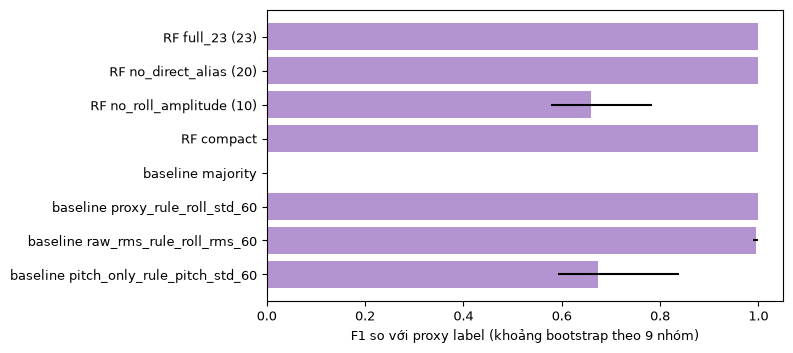

In [3]:
rows = []
for name, fs in T["feature_sets"].items():
    m, b = fs["pooled"], fs["group_bootstrap"]
    rows.append({"mô hình": f"RF {name} ({len(fs['features'])})", "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                 "PR-AUC": m["pr_auc_average_precision"], "F1 2.5%": b["f1_percentile_2_5"], "F1 97.5%": b["f1_percentile_97_5"]})
cm = T["compact_model"]
rows.append({"mô hình": "RF compact", "precision": cm["pooled"]["precision"], "recall": cm["pooled"]["recall"], "F1": cm["pooled"]["f1"],
             "PR-AUC": cm["pooled"]["pr_auc_average_precision"], "F1 2.5%": cm["group_bootstrap"]["f1_percentile_2_5"], "F1 97.5%": cm["group_bootstrap"]["f1_percentile_97_5"]})
for name, m in T["baselines"].items():
    b = m.get("group_bootstrap", {})
    rows.append({"mô hình": f"baseline {name}", "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                 "PR-AUC": np.nan, "F1 2.5%": b.get("f1_percentile_2_5", np.nan), "F1 97.5%": b.get("f1_percentile_97_5", np.nan)})
res = pd.DataFrame(rows); display(res.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
err = np.vstack([res.F1 - res["F1 2.5%"], res["F1 97.5%"] - res.F1]).clip(min=0)
ax.barh(res["mô hình"], res.F1, xerr=np.nan_to_num(err), color="tab:purple", alpha=.7)
ax.set_xlabel("F1 so với proxy label (khoảng bootstrap theo 9 nhóm)"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

F1 = 1 của RF đầy đủ và của baseline `roll_std_60` là **vòng lặp**: proxy chính là ngưỡng trên `roll_std_60`. Đây không phải độ chính xác phát hiện nguy hiểm.

## Ma trận nhầm lẫn theo nhóm độc lập

In [4]:
for name, fs in T["feature_sets"].items():
    print(name); display(pd.DataFrame(fs["per_group"])[["experiment_group", "sessions", "support_positive", "tp", "fp", "fn", "tn"]])

full_23


,experiment_group,sessions,support_positive,tp,fp,fn,tn
0,hohai|T1,1,0,0,0,0,72
1,hohai|T2,1,0,0,0,0,72
2,hohai|T3,3,0,0,0,0,216
3,hohai|T4,1,0,0,0,0,72
4,hohai|T5,1,0,0,0,0,72
5,hohai|T6,3,0,0,0,0,211
6,hohai|T7,3,27,27,0,0,166
7,hohai|T8,5,136,136,0,0,113
8,hohai|T9,3,46,46,0,0,124


no_direct_alias


,experiment_group,sessions,support_positive,tp,fp,fn,tn
0,hohai|T1,1,0,0,0,0,72
1,hohai|T2,1,0,0,0,0,72
2,hohai|T3,3,0,0,0,0,216
3,hohai|T4,1,0,0,0,0,72
4,hohai|T5,1,0,0,0,0,72
5,hohai|T6,3,0,0,0,0,211
6,hohai|T7,3,27,27,0,0,166
7,hohai|T8,5,136,136,0,0,113
8,hohai|T9,3,46,46,0,0,124


no_roll_amplitude


,experiment_group,sessions,support_positive,tp,fp,fn,tn
0,hohai|T1,1,0,0,0,0,72
1,hohai|T2,1,0,0,0,0,72
2,hohai|T3,3,0,0,0,0,216
3,hohai|T4,1,0,0,0,0,72
4,hohai|T5,1,0,0,0,0,72
5,hohai|T6,3,0,0,0,0,211
6,hohai|T7,3,27,11,0,16,166
7,hohai|T8,5,136,64,8,72,105
8,hohai|T9,3,46,38,13,8,111


## Đường PR gộp từ dự đoán outer fold

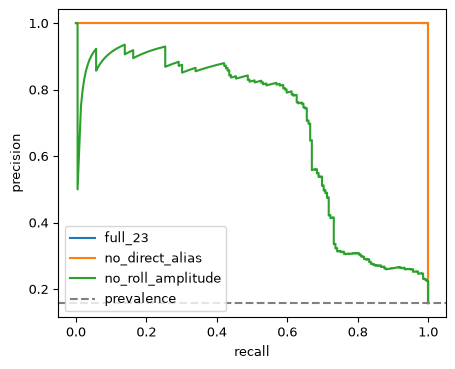

In [5]:
from sklearn.metrics import precision_recall_curve
pred = pd.read_parquet(REPO_ROOT / "ml/data/models/rf_poc_v1/outer_fold_predictions.parquet")
fig, ax = plt.subplots(figsize=(5, 4))
for name in T["feature_sets"]:
    s = pred[pred.feature_set == name]; p, r, _ = precision_recall_curve(s.y_true, s.rf_score)
    ax.plot(r, p, label=name)
ax.axhline(pred.y_true[pred.feature_set == "full_23"].mean(), ls="--", c="gray", label="prevalence")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(); plt.show()

## Hành vi trên vùng ABSTAIN (không có nhãn, không vào metric)

In [6]:
display(pd.DataFrame([{"feature set": n, "fold": f["fold"], "nhóm test": f["test_groups"][0], "ABSTAIN": f["test_abstain_windows"],
                        "RF dự đoán POS": f["test_abstain_predicted_positive"]} for n, fs in T["feature_sets"].items() for f in fs["folds"] if f["test_abstain_windows"]]))

,feature set,fold,nhóm test,ABSTAIN,RF dự đoán POS
0,full_23,5,hohai|T6,5,0
1,full_23,6,hohai|T7,23,13
2,full_23,7,hohai|T8,111,39
3,full_23,8,hohai|T9,46,21
4,no_direct_alias,5,hohai|T6,5,0
5,no_direct_alias,6,hohai|T7,23,12
6,no_direct_alias,7,hohai|T8,111,47
7,no_direct_alias,8,hohai|T9,46,24
8,no_roll_amplitude,5,hohai|T6,5,0
9,no_roll_amplitude,6,hohai|T7,23,1


## Phân tích lỗi của ablation `no_roll_amplitude`

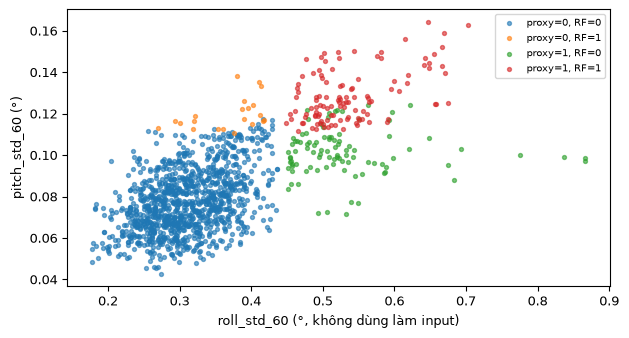

experiment_group  session_id       
hohai|T7          Berth_B_T7_Type_A     5
                  Berth_D_T7_Type_A    11
hohai|T8          Berth_B_T8_Type_A     9
                  Berth_C_T8_Type_A    13
                  Berth_D_T8_Type_A     5
                  Berth_D_T8_Type_B    11
                  Berth_D_T8_Type_C    42
hohai|T9          Berth_B_T9_Type_A     5
                  Berth_C_T9_Type_A     6
                  Berth_D_T9_Type_A    10
Name: error, dtype: int64

In [7]:
s = pred[pred.feature_set == "no_roll_amplitude"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for (yt, yp), grp in s.groupby(["y_true", "rf_pred"]):
    ax.scatter(grp.roll_std_60, grp.pitch_std_60, s=8, label=f"proxy={yt}, RF={yp}", alpha=.6)
ax.set_xlabel("roll_std_60 (°, không dùng làm input)"); ax.set_ylabel("pitch_std_60 (°)"); ax.legend(fontsize=7); plt.show()
display(s.assign(error=s.y_true != s.rf_pred).groupby(["experiment_group", "session_id"]).error.sum().loc[lambda v: v > 0])

## Feature importance (MDI mô hình cuối) và giới hạn

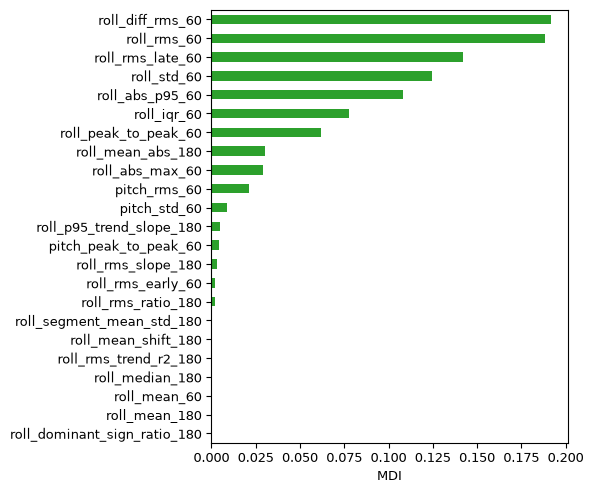

Permutation importance trên test fold, |giá trị| lớn nhất: 1.9984014443252818e-16


In [8]:
card = T["final_model_card"]
mdi = pd.Series(card["mdi_importance"]).sort_values()
mdi.plot(kind="barh", figsize=(6, 5), color="tab:green"); plt.xlabel("MDI"); plt.tight_layout(); plt.show()
perm = pd.DataFrame(T["permutation_importance_test_folds"]).drop(columns=["fold", "test_groups"])
print("Permutation importance trên test fold, |giá trị| lớn nhất:", float(perm.abs().max().max()))

Permutation importance ≈ 0 vì nhiều feature biên độ thay thế được nhau; MDI chia đều tầm quan trọng cho các feature cộng tuyến. Cả hai **không** chứng minh quan hệ nhân quả.

## Target không được huấn luyện

`AMPLITUDE_GROWTH` và `PERSISTENT_OFFSET` là NOT_TRAINABLE; notebook không tạo biểu đồ kết quả cho chúng.

## Giải thích kỹ thuật phục vụ vấn đáp cá nhân

- Pipeline giữ nhóm và không rò rỉ đã được kiểm toán; RF tái tạo được proxy trên điều kiện thử nghiệm chưa thấy.
- Ablation cho thấy thông tin đến từ biên độ Roll; khi bỏ hết, F1 ≈ baseline chỉ dùng Pitch (mức kích thích sóng chung).
- Không được mô tả các con số này là độ chính xác phát hiện hazard.